```markdown
# PHÂN TÍCH HÀNH VI KHÁCH HÀNG & CHÂN DUNG KHÁCH HÀNG MỤC TIÊU (PROBLEM 5)

Notebook này thực hiện luồng phân tích dữ liệu toàn diện từ chuẩn hóa dữ liệu thô, tính toán các độ đo chu kỳ, xây dựng chỉ số ưu tiên danh mục (Affinity Index), phân loại tập khách hàng cho đến đề xuất chương trình khuyến mãi tự động.

### Phân loại các thành phần dữ liệu tham gia:
1. **Thước đo (Measure - Dữ liệu thô):** `order_id`, `customer_id`, `order_date`, `order_status`, `quantity`, `unit_price`, `discount_amount`, `category` từ các file nguồn.
2. **Độ đo (Metric - Công thức tính toán):** `Revenue` (mặt hàng), `order_value` (đơn hàng), `Monthly_Orders`, `Monthly_Revenue`, `Monthly_AOV`, `Revenue_Growth_%`, `CustomerType`, `Affinity_Index`.
3. **Chỉ số hiệu suất cốt lõi (KPI):** `Total Orders`, `Total Revenue`, `Average Monthly Revenue`, `Peak Revenue Month`, `Repeat Customer Revenue Share (%)`, `Top Affinity Category`...
```

In [221]:
# 1 — KHỞI TẠO THƯ VIỆN & CẤU HÌNH
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:,.2f}".format)

In [222]:
# 2 — ĐỌC VÀ CHUẨN HÓA DỮ LIỆU ĐẦU VÀO (MEASURE)
# Đọc dữ liệu thô từ các tập tin nguồn
orders = pd.read_csv("/content/orders.csv")
order_items = pd.read_csv("/content/Order_items.csv", low_memory=False)
customers = pd.read_csv("/content/customers_silver.csv")
products = pd.read_csv("/content/silver_product.csv")

# Loại bỏ ký tự BOM và khoảng trắng thừa ở tiêu đề cột để tránh lỗi truy xuất
for df in [orders, order_items, customers, products]:
    df.columns = df.columns.str.replace("\ufeff", "", regex=False).str.strip()

# Chuẩn hóa kiểu dữ liệu cho các cột phân tích
orders["order_date"] = pd.to_datetime(orders["order_date"], errors="coerce")
for col in ["quantity", "unit_price", "discount_amount"]:
    order_items[col] = pd.to_numeric(order_items[col], errors="coerce")

print(f"Orders: {orders.shape} | Order Items: {order_items.shape} | Customers: {customers.shape} | Products: {products.shape}")

Orders: (646945, 9) | Order Items: (714653, 7) | Customers: (121930, 6) | Products: (2412, 8)


```markdown
## XÂY DỰNG ĐỘ ĐO (METRIC) & CHỈ SỐ CỐT LÕI (KPI)
```

In [223]:
# 3 — TÍNH TOÁN DOANH THU & QUY MÔ ĐƠN HÀNG (METRIC)
# Tính doanh thu thực tế sau giảm giá cho từng mặt hàng (Metric)
order_items["Revenue"] = (order_items["quantity"] * order_items["unit_price"]) - order_items["discount_amount"]

# Gom nhóm tính tổng quan giá trị đơn hàng cấp Order (Metric)
order_summary = order_items.groupby("order_id").agg(
    order_value=("Revenue", "sum"),
    total_quantity=("quantity", "sum"),
    distinct_products=("product_id", "nunique")
).reset_index()
display(order_summary.head())
# Chỉ lọc và giữ lại các đơn hàng có trạng thái thành công "Delivered"
valid_orders = orders[orders["order_status"].str.lower() == "delivered"].copy()
valid_orders = valid_orders.merge(order_summary, on="order_id", how="inner")
valid_orders["Month"] = valid_orders["order_date"].dt.to_period("M").astype(str)
display(valid_orders[["order_id","order_date","customer_id","order_status"]].head())
print(f"Số đơn hàng Delivered hợp lệ: {valid_orders.shape}")

,order_id,order_value,total_quantity,distinct_products
0,1,"7,967.54",7,1
1,2,"71,163.75",7,1
2,3,"33,660.99",3,1
3,4,"53,196.25",5,1
4,6,"1,597.84",1,1


,order_id,order_date,customer_id,order_status
0,1,2012-07-04,58578,delivered
1,3,2012-07-04,58811,delivered
2,4,2012-07-04,59453,delivered
3,6,2012-07-06,57821,delivered
4,7,2012-07-06,57820,delivered


Số đơn hàng Delivered hợp lệ: (516716, 13)


In [224]:
# 4 — PHÂN TÍCH XU HƯỚNG THEO THỜI GIAN (METRIC & KPI)
monthly_analysis = valid_orders.groupby("Month").agg(
    Monthly_Orders=("order_id", "nunique"),
    Monthly_Revenue=("order_value", "sum")
).reset_index().sort_values("Month").reset_index(drop=True)

# Tính toán giá trị đơn hàng trung bình (AOV) và tỷ lệ tăng trưởng MoM (Metric)
monthly_analysis["Monthly_AOV"] = monthly_analysis["Monthly_Revenue"] / monthly_analysis["Monthly_Orders"]
monthly_analysis["Revenue_Growth_%"] = monthly_analysis["Monthly_Revenue"].pct_change() * 100
monthly_analysis["Order_Growth_%"] = monthly_analysis["Monthly_Orders"].pct_change() * 100

display(monthly_analysis.head())

,Month,Monthly_Orders,Monthly_Revenue,Monthly_AOV,Revenue_Growth_%,Order_Growth_%
0,2012-07,4233,"104,984,081.31","24,801.34",NaN,NaN
1,2012-08,5132,"127,270,283.79","24,799.35",21.23,21.24
2,2012-09,4202,"102,107,552.64","24,299.75",-19.77,-18.12
3,2012-10,3420,"87,250,357.30","25,511.80",-14.55,-18.61
4,2012-11,3279,"77,207,538.25","23,546.06",-11.51,-4.12


In [225]:
# 4.1 — Q3: XÁC ĐỊNH THỜI ĐIỂM MUA SẮM CAO ĐIỂM (PEAK SHOPPING PERIOD)
# Tìm tháng có doanh thu cao nhất
peak_revenue_row = monthly_analysis.loc[monthly_analysis["Monthly_Revenue"].idxmax()]
# Tìm tháng có lượng đơn hàng lớn nhất
peak_order_row = monthly_analysis.loc[monthly_analysis["Monthly_Orders"].idxmax()]

print("=========================================================")
print("📊 THỜI ĐIỂM MUA SẮM CAO ĐIỂM NHẤT (PEAK SHOPPING PERIOD)")
print("=========================================================")
print(f"Tháng có DOANH THU cao nhất: {peak_revenue_row['Month']}")
print(f"  -> Tổng doanh thu: {peak_revenue_row['Monthly_Revenue']:,.2f} VND")
print(f"  -> Số lượng đơn hàng: {peak_revenue_row['Monthly_Orders']:,} đơn")
print(f"  -> Giá trị đơn hàng trung bình (AOV): {peak_revenue_row['Monthly_AOV']:,.2f} VND")
print("---------------------------------------------------------")
print(f"Tháng có SỐ LƯỢNG ĐƠN HÀNG cao nhất: {peak_order_row['Month']}")
print(f"  -> Số lượng đơn hàng: {peak_order_row['Monthly_Orders']:,} đơn")
print(f"  -> Tổng doanh thu: {peak_order_row['Monthly_Revenue']:,.2f} VND")
print(f"  -> Giá trị đơn hàng trung bình (AOV): {peak_order_row['Monthly_AOV']:,.2f} VND")
print("=========================================================")

📊 THỜI ĐIỂM MUA SẮM CAO ĐIỂM NHẤT (PEAK SHOPPING PERIOD)
Tháng có DOANH THU cao nhất: 2016-05
  -> Tổng doanh thu: 214,964,610.97 VND
  -> Số lượng đơn hàng: 7,964 đơn
  -> Giá trị đơn hàng trung bình (AOV): 26,992.04 VND
---------------------------------------------------------
Tháng có SỐ LƯỢNG ĐƠN HÀNG cao nhất: 2018-06
  -> Số lượng đơn hàng: 8,774 đơn
  -> Tổng doanh thu: 209,593,587.62 VND
  -> Giá trị đơn hàng trung bình (AOV): 23,888.03 VND


In [226]:
# 5 — PHÂN TÍCH DOANH THU THEO DANH MỤC SẢN PHẨM
order_items_category = order_items.merge(products[["product_id", "category"]], on="product_id", how="left")
order_items_category = order_items_category.merge(
    valid_orders[["order_id", "customer_id", "order_date", "Month"]],
    on="order_id",
    how="inner"
)
display(order_items_category.head())
category_analysis = order_items_category.groupby("category").agg(
    Orders=("order_id", "nunique"),
    Quantity=("quantity", "sum"),
    Revenue=("Revenue", "sum")
).reset_index()

category_analysis["Category_Revenue_Share_%"] = (category_analysis["Revenue"] / category_analysis["Revenue"].sum()) * 100
category_analysis = category_analysis.sort_values("Revenue", ascending=False).reset_index(drop=True)

display(category_analysis)

,order_id,product_id,promo_id,promo_id_2,quantity,unit_price,discount_amount,Revenue,category,customer_id,order_date,Month
0,1,2400,NaN,NaN,7,"1,138.22",0.00,"7,967.54",GenZ,58578,2012-07-04,2012-07
1,3,396,NaN,NaN,3,"11,220.33",0.00,"33,660.99",Streetwear,58811,2012-07-04,2012-07
2,4,635,NaN,NaN,5,"10,639.25",0.00,"53,196.25",Streetwear,59453,2012-07-04,2012-07
3,6,1935,NaN,NaN,1,"1,597.84",0.00,"1,597.84",Outdoor,57821,2012-07-06,2012-07
4,7,1934,NaN,NaN,6,"1,633.49",0.00,"9,800.94",Outdoor,57820,2012-07-06,2012-07


,category,Orders,Quantity,Revenue,Category_Revenue_Share_%
0,Streetwear,311254,1413433,"10,030,049,307.33",80.12
1,Outdoor,160000,933785,"1,875,828,852.01",14.98
2,Casual,18805,85457,"349,094,263.72",2.79
3,GenZ,29617,133255,"263,203,324.15",2.10


In [227]:
# 6 — PHÂN LOẠI & SO SÁNH HÀNH VI KHÁCH HÀNG (METRIC)
customer_analysis = valid_orders.groupby("customer_id").agg(
    CustomerRevenue=("order_value", "sum"),
    PurchaseFrequency=("order_id", "nunique"),
    Customer_AOV=("order_value", "mean"),
    Customer_BasketSize=("total_quantity", "mean")
).reset_index()

# Xác định nhóm khách hàng dựa trên tần suất mua hàng thực tế (Metric)
customer_analysis["CustomerType"] = np.where(
    customer_analysis["PurchaseFrequency"] > 1,
    "Repeat Customer",
    "One-time Buyer"
)

customer_type_behavior = valid_orders.merge(
    customer_analysis[["customer_id", "CustomerType"]], on="customer_id", how="left"
).groupby("CustomerType").agg(
    Customer_Count=("customer_id", "nunique"),
    Order_Count=("order_id", "nunique"),
    Revenue=("order_value", "sum"),
    AOV=("order_value", "mean"),
    Basket_Size=("total_quantity", "mean")
).reset_index()

customer_type_behavior["Revenue_Share_%"] = (customer_type_behavior["Revenue"] / customer_type_behavior["Revenue"].sum()) * 100
display(customer_type_behavior)

,CustomerType,Customer_Count,Order_Count,Revenue,AOV,Basket_Size,Revenue_Share_%
0,One-time Buyer,22843,22843,"548,075,527.53","23,993.15",4.94,4.38
1,Repeat Customer,62272,493873,"11,970,100,219.67","24,237.20",4.97,95.62


In [228]:
# 7 — CHỈ SỐ ƯU TIÊN DANH MỤC & ĐỀ XUẤT HÀNH ĐỘNG (AFFINITY INDEX)
customer_category_data = order_items_category.merge(
    customer_analysis[["customer_id", "CustomerType"]], on="customer_id", how="left"
)

customer_category_behavior = customer_category_data.groupby(["CustomerType", "category"]).agg(
    Orders=("order_id", "nunique"),
    Quantity=("quantity", "sum"),
    Revenue=("Revenue", "sum")
).reset_index()

customer_category_behavior["Category_Revenue_Share_%"] = (
    customer_category_behavior["Revenue"] /
    customer_category_behavior.groupby("CustomerType")["Revenue"].transform("sum") * 100
)

customer_category_behavior = customer_category_behavior.merge(
    category_analysis[["category", "Category_Revenue_Share_%"]].rename(columns={"Category_Revenue_Share_%": "Baseline_Share_%"}),
    on="category",
    how="left"
)

# Tính chỉ số ưa thích danh mục Affinity Index để tìm đặc trưng hành vi riêng biệt
customer_category_behavior["Affinity_Index"] = (
    customer_category_behavior["Category_Revenue_Share_%"] / customer_category_behavior["Baseline_Share_%"] * 100
)

# Lọc lấy top 2 danh mục có mức độ ưu tiên đặc trưng nhất (giới hạn doanh thu tối thiểu >= 2% để tránh nhiễu)
MIN_REVENUE_SHARE = 2
top_category_by_customer_type = (
    customer_category_behavior[customer_category_behavior["Category_Revenue_Share_%"] >= MIN_REVENUE_SHARE]
    .sort_values(["CustomerType", "Affinity_Index"], ascending=[True, False])
    .groupby("CustomerType")
    .head(2)
    .reset_index(drop=True)
)

display(top_category_by_customer_type)

,CustomerType,category,Orders,Quantity,Revenue,Category_Revenue_Share_%,Baseline_Share_%,Affinity_Index
0,One-time Buyer,Casual,904,4218,"15,609,653.21",2.85,2.79,102.13
1,One-time Buyer,Streetwear,13692,61785,"445,014,703.97",81.20,80.12,101.34
2,Repeat Customer,GenZ,28428,128047,"253,071,636.51",2.11,2.10,100.55
3,Repeat Customer,Outdoor,152934,892062,"1,798,509,369.29",15.03,14.98,100.27


In [229]:
# 8 — XÂY DỰNG KHUNG ĐỀ XUẤT CHIẾN DỊCH CRM
recommendation_base = top_category_by_customer_type.merge(
    customer_type_behavior[["CustomerType", "Customer_Count", "Order_Count", "Revenue", "AOV", "Basket_Size", "Revenue_Share_%"]],
    on="CustomerType",
    how="left",
    suffixes=("_Category", "_CustomerType")
)

def generate_crm_strategy(row):
    c_type, cat = row["CustomerType"], row["category"]
    if c_type == "Repeat Customer":
        promo = f"Ưu đãi dành cho khách hàng quay lại đối với nhóm sản phẩm {cat}"
        prod = f"Gợi ý sản phẩm thuộc danh mục {cat} và các sản phẩm liên quan"
    else:
        promo = f"Khuyến mãi kích thích mua lại đối với nhóm sản phẩm {cat}"
        prod = f"Gợi ý sản phẩm thuộc danh mục {cat} để khuyến khích lần mua tiếp theo"
    return pd.Series([promo, prod])

recommendation_base[["Suggested_Promotion", "Suggested_Product_Action"]] = recommendation_base.apply(generate_crm_strategy, axis=1)
display(recommendation_base[["CustomerType", "category", "Affinity_Index", "Suggested_Promotion", "Suggested_Product_Action"]])

,CustomerType,category,Affinity_Index,Suggested_Promotion,Suggested_Product_Action
0,One-time Buyer,Casual,102.13,Khuyến mãi kích thích mua lại đối với nhóm sản...,Gợi ý sản phẩm thuộc danh mục Casual để khuyến...
1,One-time Buyer,Streetwear,101.34,Khuyến mãi kích thích mua lại đối với nhóm sản...,Gợi ý sản phẩm thuộc danh mục Streetwear để kh...
2,Repeat Customer,GenZ,100.55,Ưu đãi dành cho khách hàng quay lại đối với nh...,Gợi ý sản phẩm thuộc danh mục GenZ và các sản ...
3,Repeat Customer,Outdoor,100.27,Ưu đãi dành cho khách hàng quay lại đối với nh...,Gợi ý sản phẩm thuộc danh mục Outdoor và các s...


```markdown
## BIỂU DIỄN TRỰC QUAN (VISUALIZATION)
```

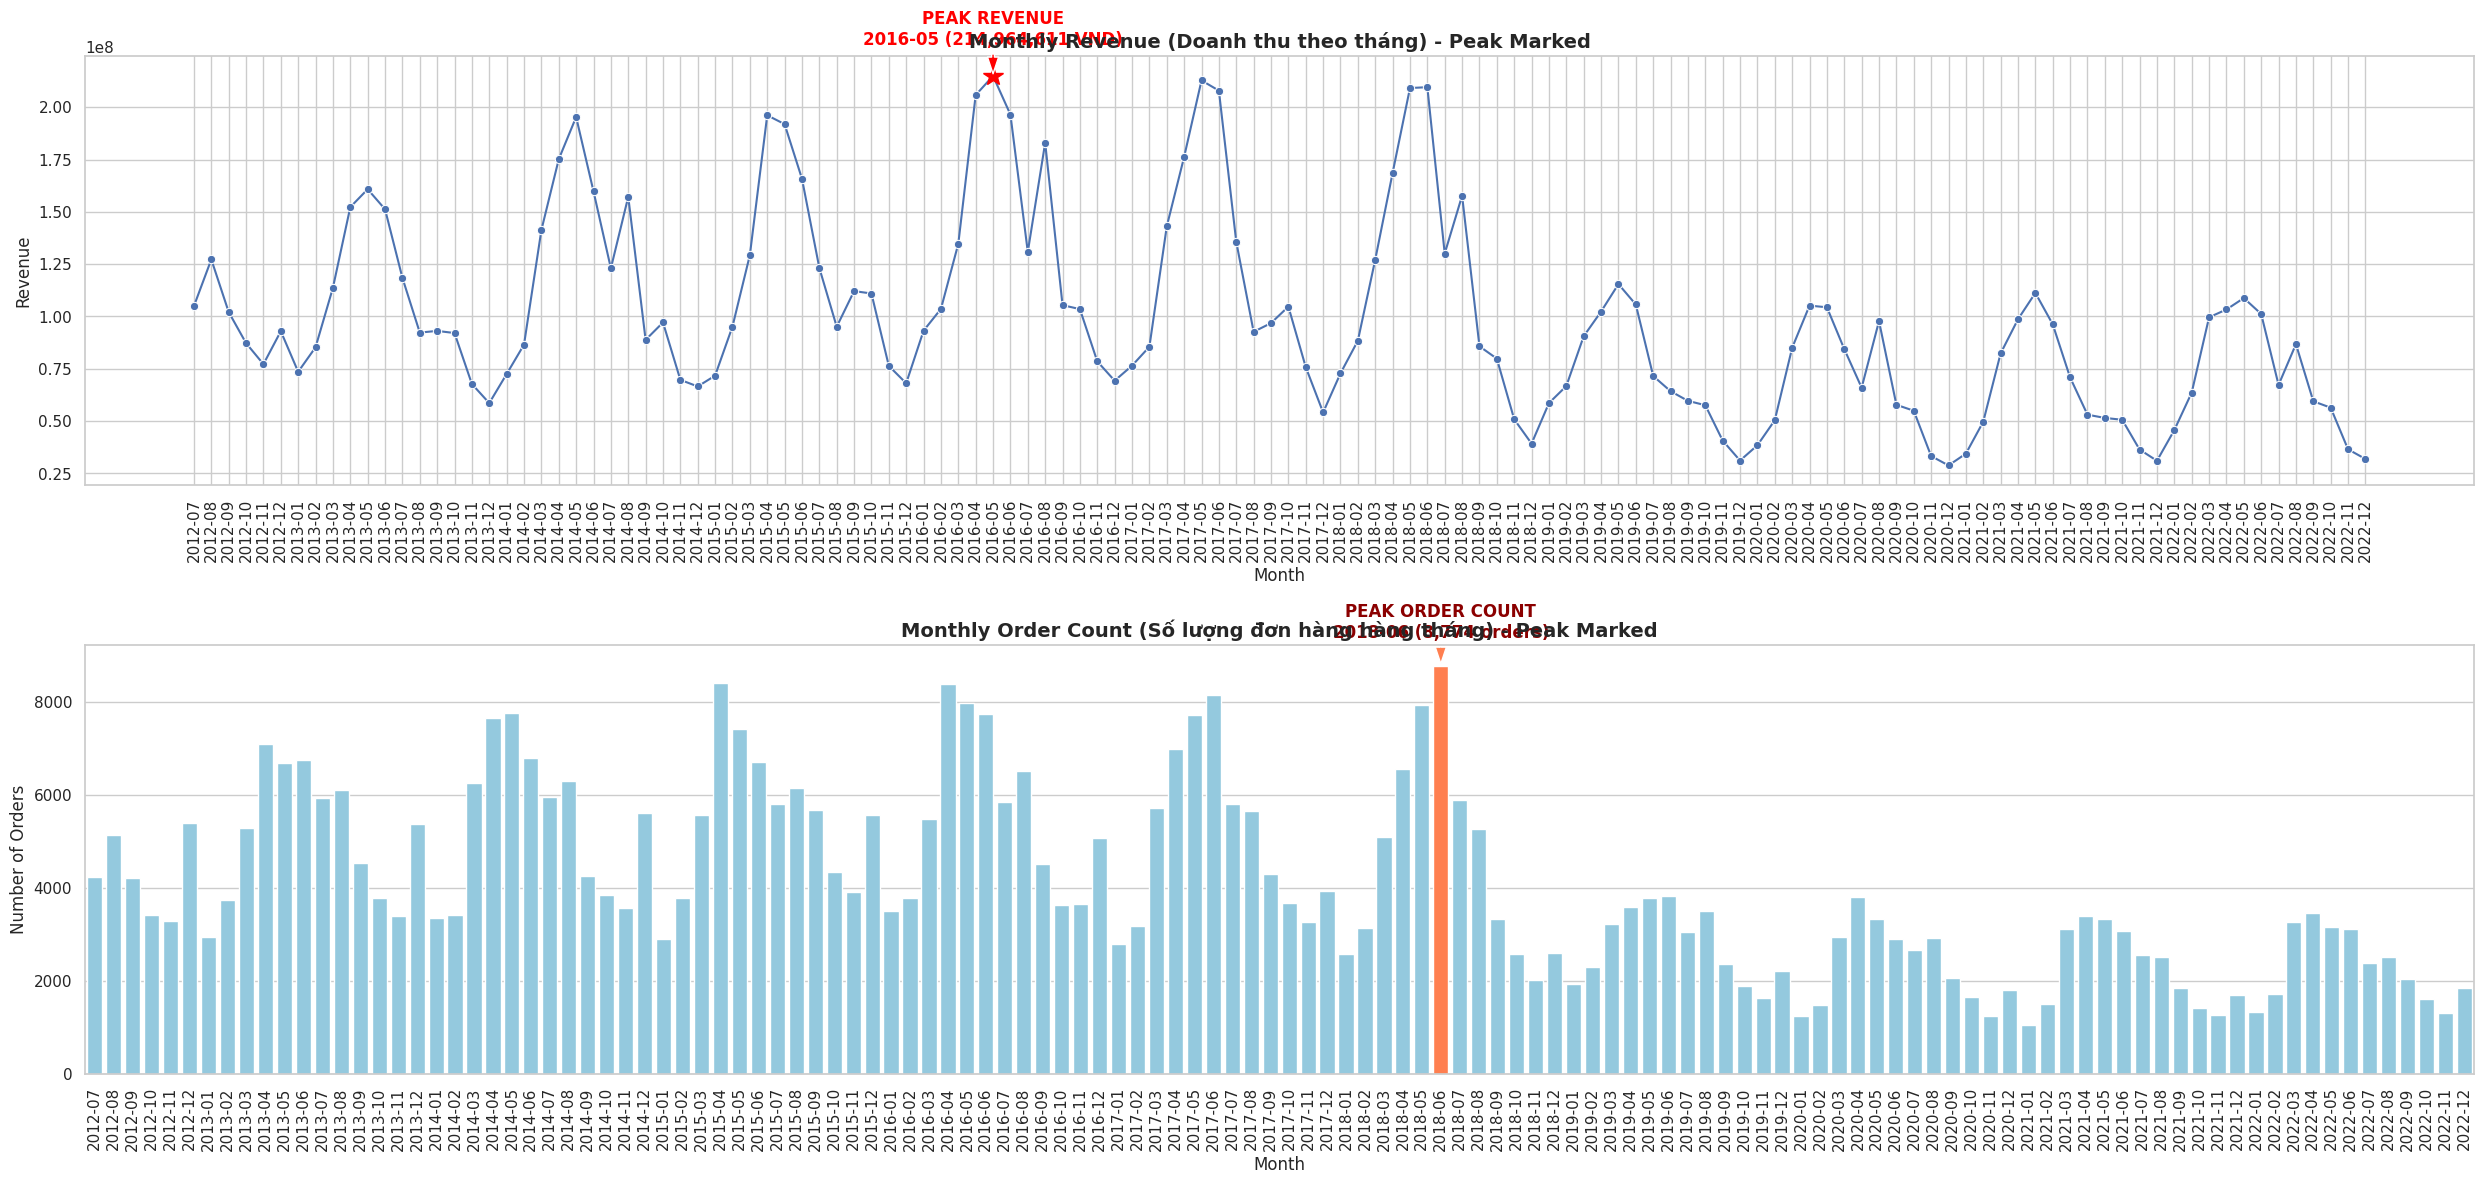

In [234]:
# 9 — ĐỒ THỊ DOANH THU & ĐƠN HÀNG HÀNG THÁNG (CÓ ĐÁNH DẤU THỜI ĐIỂM CAO ĐIỂM)
fig, axes = plt.subplots(2, 1, figsize=(25, 12))

# Lineplot Doanh thu hàng tháng
sns.lineplot(data=monthly_analysis, x="Month", y="Monthly_Revenue", marker="o", color="b", ax=axes[0])
axes[0].set_title("Monthly Revenue (Doanh thu theo tháng) - Peak Marked", fontsize=14, fontweight="bold")
axes[0].set_xlabel("Month")
axes[0].set_ylabel("Revenue")
axes[0].tick_params(axis='x', rotation=90)

# Tìm tọa độ x và y của điểm Peak Revenue
peak_rev_x = peak_revenue_month
peak_rev_y = peak_revenue

# Đánh dấu đỉnh doanh thu trên đồ thị line
axes[0].plot(peak_rev_x, peak_rev_y, marker='*', color='red', markersize=15, label="Peak Revenue Month")
axes[0].annotate(f"PEAK REVENUE\n{peak_rev_x} ({peak_rev_y:,.0f} VND)",
                 xy=(peak_rev_x, peak_rev_y),
                 xytext=(peak_rev_x, peak_rev_y + 15000000),
                 arrowprops=dict(facecolor='red', shrink=0.08, width=2, headwidth=8),
                 fontsize=12, color='red', weight='bold', ha='center')

# Barplot Số lượng đơn hàng hàng tháng
sns.barplot(data=monthly_analysis, x="Month", y="Monthly_Orders", color="skyblue", ax=axes[1])
axes[1].set_title("Monthly Order Count (Số lượng đơn hàng hàng tháng) - Peak Marked", fontsize=14, fontweight="bold")
axes[1].set_xlabel("Month")
axes[1].set_ylabel("Number of Orders")
axes[1].tick_params(axis='x', rotation=90)

# Tìm vị trí index của tháng cao điểm để xác định vị trí cột trên barplot
all_months_list = list(monthly_analysis["Month"])
peak_ord_idx = all_months_list.index(peak_order_month)
peak_ord_y = peak_order_count

# Tô màu khác biệt cho cột cao điểm nhất và thêm nhãn vẽ mũi tên chỉ vào cột
axes[1].patches[peak_ord_idx].set_facecolor('coral')
axes[1].annotate(f"PEAK ORDER COUNT\n{peak_order_month} ({peak_ord_y:,} orders)",
                 xy=(peak_ord_idx, peak_ord_y),
                 xytext=(peak_ord_idx, peak_ord_y + 600),
                 arrowprops=dict(facecolor='coral', shrink=0.08, width=2, headwidth=8),
                 fontsize=12, color='darkred', weight='bold', ha='center')

plt.tight_layout()
plt.show()

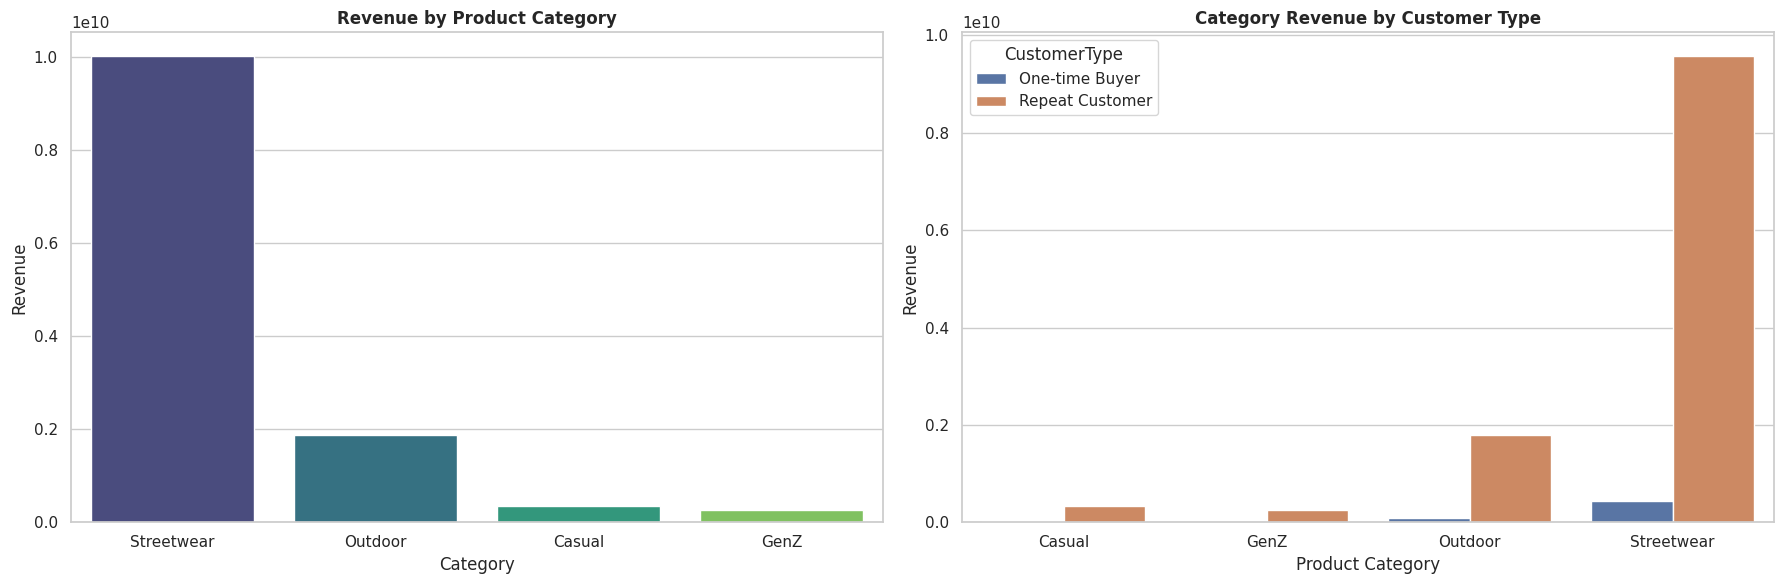

In [231]:
# 10 — TRỰC QUAN HÓA DOANH THU THEO CATEGORY & NHÓM KHÁCH HÀNG
fig, axes = plt.subplots(1, 2, figsize=(18, 6))

sns.barplot(data=category_analysis, x="category", y="Revenue", hue="category", palette="viridis", legend=False, ax=axes[0])
axes[0].set_title("Revenue by Product Category", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Category")
axes[0].set_ylabel("Revenue")

sns.barplot(data=customer_category_behavior, x="category", y="Revenue", hue="CustomerType", ax=axes[1])
axes[1].set_title("Category Revenue by Customer Type", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Product Category")
axes[1].set_ylabel("Revenue")

plt.tight_layout()
plt.show()

## BỔ SUNG: CÔNG CỤ KHÁM PHÁ CHIẾN DỊCH CRM TƯƠNG TÁC (INTERACTIVE CRM DASHBOARD)

In [232]:
import ipywidgets as widgets
from ipywidgets import interact

def show_crm_dashboard(customer_group):
    print(f"=== BÁO CÁO PHÂN KHÚC: {customer_group.upper()} ===\n")

    # Lọc thông tin nhóm khách hàng
    group_info = customer_type_behavior[customer_type_behavior['CustomerType'] == customer_group].iloc[0]
    print(f"👥 Quy mô nhóm khách hàng:")
    print(f"  - Số lượng khách hàng: {group_info['Customer_Count']:,} người")
    print(f"  - Số lượng đơn hàng thành công: {group_info['Order_Count']:,} đơn")
    print(f"  - Đóng góp doanh thu: {group_info['Revenue']:,.2f} VND ({group_info['Revenue_Share_%']:.2f}% tổng doanh thu)")
    print(f"  - Giá trị đơn hàng trung bình (AOV): {group_info['AOV']:,.2f} VND")
    print(f"  - Kích thước giỏ hàng trung bình (Basket Size): {group_info['Basket_Size']:.2f} sản phẩm\n")

    # Lọc đề xuất chiến dịch tương ứng từ recommendation_base
    strategies = recommendation_base[recommendation_base['CustomerType'] == customer_group]
    print(f"🎯 Đề xuất danh mục sản phẩm & Hành động CRM (Ưu tiên theo Affinity Index):")
    for idx, row in strategies.iterrows():
        print(f"  ▫️ Danh mục: {row['category']} (Affinity Index: {row['Affinity_Index']:.2f})")
        print(f"     -> Chiêu thị: {row['Suggested_Promotion']}")
        print(f"     -> Gợi ý sản phẩm: {row['Suggested_Product_Action']}\n")

# Khởi tạo widget tương tác
group_dropdown = widgets.Dropdown(
    options=['Repeat Customer', 'One-time Buyer'],
    value='Repeat Customer',
    description='Chọn Nhóm:',
    disabled=False,
)

interact(show_crm_dashboard, customer_group=group_dropdown);

interactive(children=(Dropdown(description='Chọn Nhóm:', options=('Repeat Customer', 'One-time Buyer'), value=…

```markdown
## BẢNG ĐO LƯỜNG TỔNG HỢP KPI & KIỂM TRA ĐỘ CHÍNH XÁC (VALIDATION)
```

In [233]:
# 11 — TỔNG HỢP KPI CHÍNH
total_orders = valid_orders["order_id"].nunique()
total_revenue = valid_orders["order_value"].sum()
avg_monthly_orders = monthly_analysis["Monthly_Orders"].mean()
avg_monthly_revenue = monthly_analysis["Monthly_Revenue"].mean()
avg_revenue_growth = monthly_analysis["Revenue_Growth_%"].mean()
avg_order_growth = monthly_analysis["Order_Growth_%"].mean()

# Tìm kiếm các mốc mua sắm đỉnh điểm (Peak Months)
peak_rev_idx = monthly_analysis["Monthly_Revenue"].idxmax()
peak_revenue_month = monthly_analysis.loc[peak_rev_idx, "Month"]
peak_revenue = monthly_analysis.loc[peak_rev_idx, "Monthly_Revenue"]

peak_ord_idx = monthly_analysis["Monthly_Orders"].idxmax()
peak_order_month = monthly_analysis.loc[peak_ord_idx, "Month"]
peak_order_count = monthly_analysis.loc[peak_ord_idx, "Monthly_Orders"]

# Thông tin danh mục và phân khúc
top_cat_row = category_analysis.iloc[0]
repeat_cust_row = customer_type_behavior[customer_type_behavior["CustomerType"] == "Repeat Customer"].iloc[0]
one_time_cust_row = customer_type_behavior[customer_type_behavior["CustomerType"] == "One-time Buyer"].iloc[0]

ps5_kpi = pd.DataFrame({
    "KPI": [
        "Total Orders", "Total Revenue", "Average Monthly Orders", "Average Monthly Revenue",
        "Average Revenue Growth (%)", "Average Order Growth (%)", "Peak Revenue Month", "Peak Revenue",
        "Peak Order Month", "Peak Order Count", "Top Product Category (Overall)", "Top Category Revenue Share (%)",
        "Repeat Customer Revenue Share (%)", "One-time Buyer Revenue Share (%)"
    ],
    "Value": [
        total_orders, total_revenue, avg_monthly_orders, avg_monthly_revenue,
        avg_revenue_growth, avg_order_growth, peak_revenue_month, peak_revenue,
        peak_order_month, peak_order_count, top_cat_row["category"], top_cat_row["Category_Revenue_Share_%"],
        repeat_cust_row["Revenue_Share_%"], one_time_cust_row["Revenue_Share_%"]
    ]
})

display(ps5_kpi)

,KPI,Value
0,Total Orders,516716
1,Total Revenue,"12,518,175,747.20"
2,Average Monthly Orders,"4,100.92"
3,Average Monthly Revenue,"99,350,601.17"
4,Average Revenue Growth (%),2.78
5,Average Order Growth (%),3.77
6,Peak Revenue Month,2016-05
7,Peak Revenue,"214,964,610.97"
8,Peak Order Month,2018-06
9,Peak Order Count,8774


# TÀI LIỆU ĐẶC TẢ CHI TIẾT: MEASURE, METRIC VÀ KPI (PROBLEM 5)

Dưới đây là bản đặc tả kỹ thuật chi tiết nhất về các thành phần dữ liệu tham gia vào luồng xử lý phân tích hành vi và chân dung khách hàng mục tiêu.

---

## 1. THƯỚC ĐO (MEASURE) - DỮ LIỆU ĐẦU VÀO THÔ
Đây là các cột dữ liệu gốc thu thập trực tiếp từ các file CSV nguồn, chưa qua bất kỳ bước xử lý hay tính toán tổng hợp nào:

| Tên Thước Đo (Measure) | Nguồn CSV | Ý Nghĩa Kỹ Thuật | Vai Trò Trong Luồng Xử Lý |
| :--- | :--- | :--- | :--- |
| `order_id` | `orders.csv` | Mã định danh duy nhất của mỗi đơn hàng | Khóa chính để đếm số giao dịch độc nhất và thực hiện `groupby`. |
| `customer_id` | `orders.csv` | Mã định danh duy nhất của từng khách hàng | Dùng để nhóm các đơn hàng theo khách hàng và phân loại tập khách hàng. |
| `order_date` | `orders.csv` | Ngày giờ thực hiện giao dịch thô | Trích xuất thành cột chuỗi thời gian dạng `Period("M")` (Tháng/Năm). |
| `order_status` | `orders.csv` | Trạng thái đơn hàng | Bộ lọc bắt buộc (`order_status.str.lower() == 'delivered'`) loại bỏ đơn hủy/trả. |
| `quantity` | `Order_items.csv` | Số lượng sản phẩm thô | Số lượng đơn vị sản phẩm mua trên mỗi dòng hóa đơn. |
| `unit_price` | `Order_items.csv` | Đơn giá thô của một sản phẩm | Giá bán gốc của một sản phẩm trước khi áp dụng chiết khấu. |
| `discount_amount`| `Order_items.csv` | Giá trị chiết khấu áp dụng | Số tiền giảm giá trực tiếp lên dòng sản phẩm đó. |
| `category` | `silver_product.csv`| Tên danh mục phân loại của sản phẩm | Chiều phân tích để hiểu thị hiếu sản phẩm của từng nhóm khách hàng. |

---

## 2. ĐỘ ĐO (METRIC) - CÔNG THỨC & CÁCH TÍNH TOÁN CHI TIẾT (PANDAS & NUMPY)
Đây là các cột giá trị được tính toán từ các thước đo thô ở trên qua các phép toán gom nhóm (`groupby`), biến đổi chuỗi thời gian, hoặc các công thức tỷ trọng:

### A. Doanh thu & Quy mô Đơn hàng
*   **`Revenue` (Doanh thu thực tế trên từng dòng sản phẩm):**
    *   *Công thức toán học:*
        $$\text{Revenue} = (\text{quantity} \times \text{unit\_price}) - \text{discount\_amount}$$
    *   *Mã nguồn Pandas:*
        ```python
        order_items['Revenue'] = (order_items['quantity'] * order_items['unit_price']) - order_items['discount_amount']
        ```
*   **`order_value` (Giá trị của một đơn hàng):**
    *   *Công thức toán học:*
        $$\text{order\_value} = \sum_{i \in \text{Order}} \text{Revenue}_i$$
    *   *Mã nguồn Pandas:*
        ```python
        order_summary = order_items.groupby('order_id').agg(order_value=('Revenue', 'sum'))
        ```

### B. Chuỗi thời gian theo Tháng (TimeSeries Metrics)
*   **`Monthly_Orders` (Số đơn hàng theo tháng):**
    *   *Công thức toán học:*
        $$\text{Monthly\_Orders} = \text{CountDistinct}(\text{order\_id}) \quad \text{grouped by Month}$$
    *   *Mã nguồn Pandas:*
        ```python
        monthly_analysis = valid_orders.groupby('Month').agg(Monthly_Orders=('order_id', 'nunique'))
        ```
*   **`Monthly_Revenue` (Doanh thu theo tháng):**
    *   *Công thức toán học:*
        $$\text{Monthly\_Revenue} = \sum \text{order\_value} \quad \text{grouped by Month}$$
    *   *Mã nguồn Pandas:*
        ```python
        monthly_analysis = valid_orders.groupby('Month').agg(Monthly_Revenue=('order_value', 'sum'))
        ```
*   **`Monthly_AOV` (Giá trị đơn hàng trung bình tháng):**
    *   *Công thức toán học:*
        $$\text{Monthly\_AOV}_t = \frac{\text{Monthly\_Revenue}_t}{\text{Monthly\_Orders}_t}$$
    *   *Mã nguồn Pandas:*
        ```python
        monthly_analysis['Monthly_AOV'] = monthly_analysis['Monthly_Revenue'] / monthly_analysis['Monthly_Orders']
        ```
*   **`Revenue_Growth_%` (Phần trăm tăng trưởng doanh thu so với tháng trước - MoM):**
    *   *Công thức toán học:*
        $$\text{Revenue\_Growth\_\%}_t = \frac{\text{Monthly\_Revenue}_t - \text{Monthly\_Revenue}_{t-1}}{\text{Monthly\_Revenue}_{t-1}} \times 100$$
    *   *Mã nguồn Pandas:*
        ```python
        monthly_analysis['Revenue_Growth_%'] = monthly_analysis['Monthly_Revenue'].pct_change() * 100
        ```
*   **`Order_Growth_%` (Phần trăm tăng trưởng đơn hàng so với tháng trước - MoM):**
    *   *Công thức toán học:*
        $$\text{Order\_Growth\_\%}_t = \frac{\text{Monthly\_Orders}_t - \text{Monthly\_Orders}_{t-1}}{\text{Monthly\_Orders}_{t-1}} \times 100$$
    *   *Mã nguồn Pandas:*
        ```python
        monthly_analysis['Order_Growth_%'] = monthly_analysis['Monthly_Orders'].pct_change() * 100
        ```

### C. Phân khúc Khách hàng (Customer Segmentation Metrics)
*   **`CustomerRevenue` (Doanh thu trọn đời của từng khách hàng):**
    *   *Công thức toán học:*
        $$\text{CustomerRevenue} = \sum \text{order\_value} \quad \text{grouped by customer\_id}$$
*   **`PurchaseFrequency` (Tần suất mua hàng):**
    *   *Công thức toán học:*
        $$\text{PurchaseFrequency} = \text{CountDistinct}(\text{order\_id}) \quad \text{grouped by customer\_id}$$
*   **`CustomerType` (Phân nhóm khách hàng dựa trên hành vi thực tế):**
    *   *Công thức logic:*
        $$\text{CustomerType} = \begin{cases} \text{"Repeat Customer"}, & \text{nếu } \text{PurchaseFrequency} \ge 2 \\ \text{"One-time Buyer"}, & \text{nếu } \text{PurchaseFrequency} = 1 \end{cases}$$
    *   *Mã nguồn Pandas:*
        ```python
        customer_analysis['CustomerType'] = np.where(customer_analysis['PurchaseFrequency'] > 1, 'Repeat Customer', 'One-time Buyer')
        ```
*   **`AOV` và `Basket_Size` (Giá trị đơn hàng và Kích thước giỏ hàng trung bình theo từng nhóm):**
    *   *Mã nguồn Pandas:*
        ```python
        customer_type_behavior = valid_orders.groupby('CustomerType').agg(AOV=('order_value', 'mean'), Basket_Size=('total_quantity', 'mean'))
        ```

### D. Mức độ ưu tiên Danh mục (Affinity Metrics)
*   **`Category_Revenue_Share_%` (Tỷ trọng doanh thu danh mục của nhóm khách hàng):**
    *   *Công thức toán học:*
        $$\text{Category\_Revenue\_Share\_\%}_{\text{Nhóm, } c} = \frac{\text{Revenue}_{\text{Nhóm, } c}}{\sum_{i} \text{Revenue}_{\text{Nhóm, } i}} \times 100$$
*   **`Baseline_Share_%` (Tỷ trọng doanh thu danh mục toàn hệ thống):**
    *   *Công thức toán học:*
        $$\text{Baseline\_Share\_\%}_c = \frac{\text{Total\_Revenue}_c}{\text{Total\_Revenue}_{\text{Hệ thống}}} \times 100$$
*   **`Affinity_Index` (Chỉ số ưu tiên đặc trưng):**
    *   *Công thức toán học:*
        $$\text{Affinity\_Index}_{\text{Nhóm, } c} = \frac{\text{Category\_Revenue\_Share\_\%}_{\text{Nhóm, } c}}{\text{Baseline\_Share\_\%}_c} \times 100$$
    *   *Ý nghĩa:* Giúp tìm ra dòng sản phẩm thực sự thu hút phân khúc đó vượt lên trên mức trung bình, khắc phục sự bão hòa của danh mục thống trị (Streetwear chiếm ~80% ở mọi nơi).

---

## 3. CHỈ SỐ HIỆU SUẤT CỐT LÕI (KPI) - BẢNG ĐO LƯỜNG CHIẾN LƯỢC
Đây là các chỉ số cô đọng cuối cùng được sử dụng để báo cáo trực tiếp cho ban giám đốc và bộ phận Marketing thiết kế chương trình CRM:

*   **`Total Orders` (Tổng đơn hàng thành công):** Đạt **516,716** đơn. Đo lường sức chứa vận hành tổng thể.
*   **`Total Revenue` (Tổng doanh thu toàn hệ thống):** Đạt **12,518,175,747.20** VND. Chỉ số tài chính tối cao.
*   **`Average Monthly Orders`:** Đạt **4,100.92** đơn/tháng.
*   **`Average Monthly Revenue`:** Đạt **99,350,601.17** VND/tháng.
*   **`Peak Revenue Month` & `Peak Revenue`:** Tháng **2016-05** đạt doanh số kỷ lục **214,964,610.97** VND.
*   **`Peak Order Month` & `Peak Order Count`:** Tháng **2018-06** đạt số lượng đơn nhiều nhất với **8,774** đơn hàng.
*   **`Repeat Customer Revenue Share (%)`:** Chiếm **95.62%** doanh thu. KPI tối quan trọng chứng minh sự phụ thuộc cốt lõi vào tệp khách hàng thân thiết.
*   **`One-time Buyer Revenue Share (%)`:** Chiếm **4.38%** doanh thu.
*   **`Repeat Customer — Top Affinity Category` & `Affinity Index`:** Danh mục **GenZ** có chỉ số ưu tiên cao nhất (**100.55**).
*   **`One-time Buyer — Top Affinity Category` & `Affinity Index`:** Danh mục **Casual** có chỉ số ưu tiên cao nhất (**102.13**).
*   **`Suggested Promotion`:** KPI hành động của CRM để sinh tự động nội dung ưu đãi dựa trên phân khúc và danh mục ưu tiên tương ứng.

## BẢN ĐẶC TẢ PHÂN LOẠI CHI TIẾT THEO YÊU CẦU ĐỀ BÀI

Dưới đây là tóm tắt danh mục phân loại rõ ràng cho từng chỉ số đầu ra của dự án:

### Yêu cầu 1: Thống kê số lượng đơn hàng và doanh thu theo từng tháng
*   **Thước đo (Measure):** `order_id`, `order_date`, `order_value`
*   **Độ đo (Metric):**
    *   `Monthly_Orders` = CountDistinct(order_id) theo từng tháng.
    *   `Monthly_Revenue` = Sum(order_value) theo từng tháng.
    *   `Monthly_AOV` = Monthly_Revenue / Monthly_Orders.
    *   `Revenue_Growth_%` = (Monthly_Revenue[t] - Monthly_Revenue[t-1]) / Monthly_Revenue[t-1] * 100.
*   **KPI:** `Average Monthly Revenue`, `Average Monthly Orders`, `Average Revenue Growth (%)`.

### Yêu cầu 2: Phân tích danh mục sản phẩm ưu tiên
*   **Thước đo (Measure):** `product_id`, `category`, `Revenue`
*   **Độ đo (Metric):**
    *   `Revenue` theo danh mục = Sum(Revenue) theo nhóm sản phẩm.
    *   `Category_Revenue_Share_%` = (Revenue của danh mục / Tổng Revenue hệ thống) * 100.
*   **KPI:** `Top Product Category`, `Top Category Revenue Share (%)`.

### Yêu cầu 3: Xác định thời điểm khách hàng mua sắm cao nhất
*   **Thước đo (Measure):** `Month`, `Monthly_Revenue`, `Monthly_Orders`
*   **KPI:**
    *   `Peak Revenue Month` = Tháng đạt doanh thu lớn nhất.
    *   `Peak Order Month` = Tháng đạt số lượng đơn hàng lớn nhất.

### Yêu cầu 4: So sánh hành vi mua sắm giữa các nhóm khách hàng
*   **Thước đo (Measure):** `customer_id`, `CustomerType`, `order_value`
*   **Độ đo (Metric):**
    *   `AOV` theo nhóm = Mean(order_value) gom nhóm theo CustomerType.
    *   `Basket_Size` theo nhóm = Mean(total_quantity) gom nhóm theo CustomerType.
*   **KPI:** `Repeat Customer Revenue Share (%)`, `One-time Buyer Revenue Share (%)`.

### Yêu cầu 5: Đề xuất chương trình khuyến mãi cá nhân hóa
*   **Thước đo (Measure):** `CustomerType`, `category`, `Category_Revenue_Share_%`
*   **Độ đo (Metric):**
    *   `Affinity_Index` = (Tỷ trọng doanh thu danh mục của phân khúc / Tỷ trọng doanh thu danh mục toàn hệ thống) * 100.
*   **KPI:** `Repeat Customer - Top Affinity Category`, `One-time Buyer - Top Affinity Category`, `Suggested Promotion`.